This is the intro to my project

In [38]:
# Importing necessary tools

import glob
import os

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["image.cmap"] = "coolwarm"

print("xarray", xr.__version__)



xarray 2025.6.1


In [39]:
# Opening the Dataset

DATA_DIR = "data:/data"

all_files = sorted(glob.glob(os.path.join(DATA_DIR, "*", "*.nc")))
print(f"Found {len(all_files)} files in {DATA_DIR}")
for f in all_files[:5]:
    print("  ", os.path.relpath(f, DATA_DIR))
print("   ...")

Found 60 files in data:/data
   2009_JanFeb/10m_u_component_of_wind_stream-oper_daily-mean.nc
   2009_JanFeb/10m_v_component_of_wind_0_daily-mean.nc
   2009_JanFeb/2m_temperature_0_daily-mean.nc
   2009_JanFeb/mean_sea_level_pressure_0_daily-mean.nc
   2009_JanFeb/total_precipitation_0_daily-mean.nc
   ...


In [40]:
# Creating a subset of the main data that represents temperature
temp_files = sorted(glob.glob(os.path.join(DATA_DIR, "*", "*2m_temperature*nc")))

ds_temp = xr.open_mfdataset(temp_files, combine = "by_coords")
ds_temp

<xarray.Dataset> Size: 73MB
Dimensions:     (valid_time: 730, latitude: 105, longitude: 237)
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
Data variables:
    t2m         (valid_time, latitude, longitude) float32 73MB dask.array<chunksize=(59, 105, 237), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-12-20T19:39 GRIB to CDM+CF via cfgrib-0.9.1...

In [41]:
# Extracting the usuable DataArray from the Dataset

T2M = ds_temp["t2m"]
T2M


<xarray.DataArray 't2m' (valid_time: 730, latitude: 105, longitude: 237)> Size: 73MB
dask.array<concatenate, shape=(730, 105, 237), dtype=float32, chunksize=(62, 105, 237), chunktype=numpy.ndarray>
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      24885
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    K
    standard_name:                            unknown
    GRIB_surface:                             0.0

In [90]:
# Checking units and Fixing accordingly
print ("Units: ", T2M.attrs.get("units"))
T2M_C = T2M - 273.15
T2M_F = (T2M_C * 9/5)+ 32
T2M_C.attrs["units"] = "degC"
T2M_F.attrs["units"] = "degF"
print ("Units: ", T2M_F.attrs.get("units"))

Units:  K
Units:  degF


In [91]:
# Creating new subsets of temp that corresponds to 2009 and 2010 respectively
Temp_F = T2M_F.sel(valid_time = slice( "2009-01-01", "2010-12-31"))
display(Temp_F)

<xarray.DataArray 't2m' (valid_time: 730, latitude: 105, longitude: 237)> Size: 73MB
dask.array<add, shape=(730, 105, 237), dtype=float32, chunksize=(62, 105, 237), chunktype=numpy.ndarray>
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
Attributes:
    units:    degF

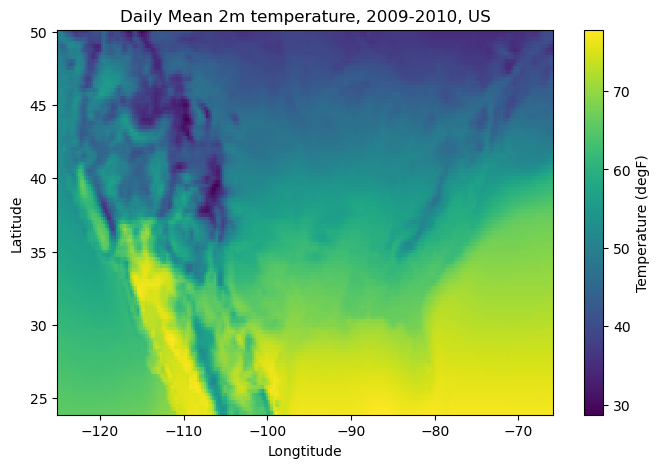

In [92]:
# Test Plot for Temperature across the US in 2009
temp_test = Temp_F.mean(dim="valid_time").plot()

plt.title("Daily Mean 2m temperature, 2009-2010, US")
plt.xlabel("Longtitude")
plt.ylabel("Latitude")
temp_test.colorbar.set_label("Temperature (degF)")
plt.show()
        


In [93]:
# Creating subset for preciptiation values 
precip_files = sorted(glob.glob(os.path.join(DATA_DIR, "*", "*total_precipitation*.nc")))

ds_precip = xr.open_mfdataset(precip_files, combine = "by_coords")
ds_precip

<xarray.Dataset> Size: 73MB
Dimensions:     (valid_time: 730, latitude: 105, longitude: 237)
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
Data variables:
    tp          (valid_time, latitude, longitude) float32 73MB dask.array<chunksize=(59, 105, 237), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-12-20T19:43 GRIB to CDM+CF via cfgrib-0.9.1...

In [94]:
#Fixing Precip Units
P = ds_precip["tp"]
print(P.attrs.get("units"))

P_mm = P*1000
P_mm.attrs["units"] = "mm/day"
print(P_mm.attrs.get("units"))

m
mm/day


In [95]:
# Seperating Precip into 2009 and 2010 
Precip = P_mm.sel(valid_time = slice("2009-01-01", "2010-12-31"))

display(Precip)



<xarray.DataArray 'tp' (valid_time: 730, latitude: 105, longitude: 237)> Size: 73MB
dask.array<mul, shape=(730, 105, 237), dtype=float32, chunksize=(62, 105, 237), chunktype=numpy.ndarray>
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
Attributes:
    units:    mm/day

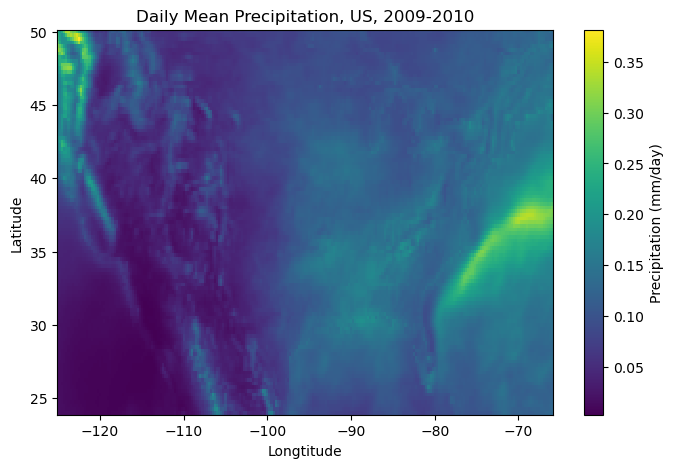

In [96]:
# Test plot for preciptiation 2009 
precip_test= Precip.mean(dim ="valid_time").plot()

plt.title("Daily Mean Precipitation, US, 2009-2010")
plt.xlabel("Longtitude")
plt.ylabel("Latitude")
precip_test.colorbar.set_label("Precipitation (mm/day)")
plt.show()

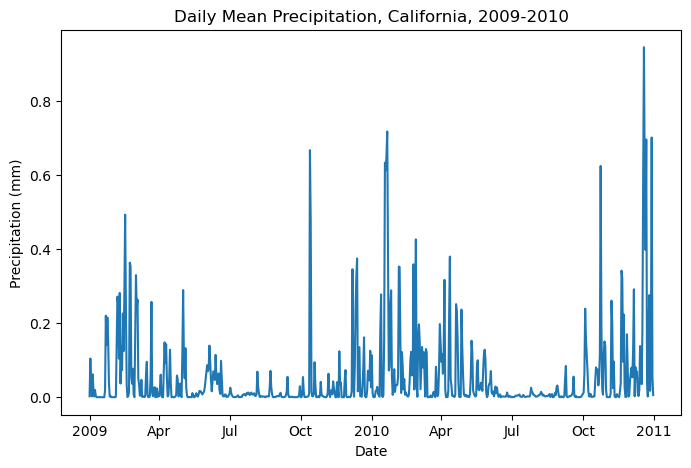

In [97]:
# New Subsets for Strictly California Precipitation

precipd_cali = Precip.sel(latitude= slice(42, 32.5), longitude= slice(-124, -114))
precipd_cali_mean = precipd_cali.mean(dim=["latitude","longitude"])
precipd_cali_mean.plot()

plt.title("Daily Mean Precipitation, California, 2009-2010")
plt.xlabel("Date")
plt.ylabel("Precipitation (mm)")
plt.show()

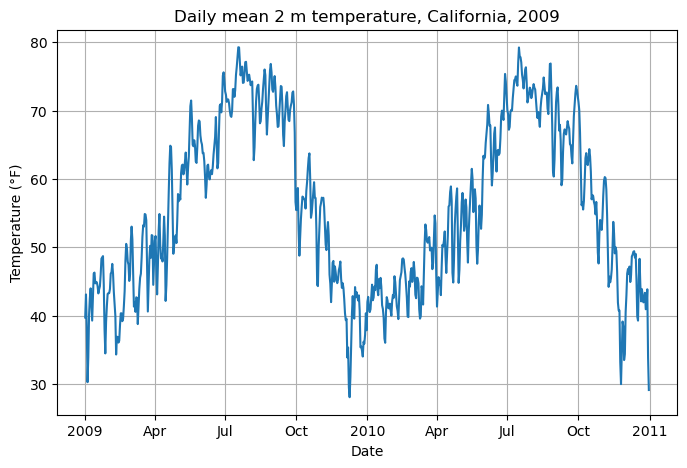

In [98]:
tempd_cali = Temp_F.sel(latitude=slice(42,32.5), longitude=slice(-124,-114))
tempd_cali_mean = tempd_cali.mean(dim=["latitude","longitude"])

tempd_cali_mean.plot()
plt.title("Daily mean 2 m temperature, California, 2009")
plt.xlabel("Date")
plt.ylabel("Temperature (°F)")
plt.grid(True)
plt.show()

In [99]:
# Create monthly averages for both temperature and precipitation
Temp_monthly =tempd_cali.resample(valid_time = "1MS").mean()
Precip_monthly = precipd_cali.resample(valid_time = "1MS").sum()

print(Temp_monthly)
print(Precip_monthly)


<xarray.DataArray 't2m' (valid_time: 24, latitude: 39, longitude: 41)> Size: 154kB
dask.array<stack, shape=(24, 39, 41), dtype=float32, chunksize=(1, 39, 41), chunktype=numpy.ndarray>
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 312B 42.0 41.75 41.5 ... 33.0 32.75 32.5
  * longitude   (longitude) float64 328B -124.0 -123.8 -123.5 ... -114.2 -114.0
  * valid_time  (valid_time) datetime64[ns] 192B 2009-01-01 ... 2010-12-01
Attributes:
    units:    degF
<xarray.DataArray 'tp' (valid_time: 24, latitude: 39, longitude: 41)> Size: 154kB
dask.array<stack, shape=(24, 39, 41), dtype=float32, chunksize=(1, 39, 41), chunktype=numpy.ndarray>
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 312B 42.0 41.75 41.5 ... 33.0 32.75 32.5
  * longitude   (longitude) float64 328B -124.0 -123.8 -123.5 ... -114.2 -114.0
  * valid_time  (valid_time) datetime64[ns] 192B 2009-01-01 ... 2010-12-01
Attributes:
    units:    mm/day


In [100]:
# Calculate Mean and Standard Deviation for precipitation
monthly_precip_mean = Precip_monthly.groupby("valid_time.month").mean("valid_time")
monthly_precip_std = Precip_monthly.groupby("valid_time.month").std("valid_time")

In [105]:
# Calculating Precipitation Anomalies and Finding Drought Months
def calculate_anomaly(group): 
    anomaly = (
        group - group.mean(dim="valid_time")
    ) / group.std(dim="valid_time")
    return anomaly


precip_anomaly = Precip_monthly.groupby("valid_time.month").map(calculate_anomaly)

drought_labels = (precip_anomaly <= -1.0).astype(int)

In [106]:
# Defining train/test data and target variables (2009/2010 respectively)
Temp_train = Temp_monthly.sel(valid_time = slice("2009-01-01", "2009-12-31"))
Temp_test = Temp_monthly.sel(valid_time = slice("2010-01-01", "2010-12-31"))

Precip_train = Precip_monthly.sel(valid_time = slice("2009-01-01", "2009-12-31"))
Precip_test = Precip_monthly.sel(valid_time = slice("2010-01-01", "2010-12-31"))

y_train = drought_labels.sel(valid_time = slice("2009-01-01", "2009-12-31"))
y_test = drought_labels.sel(valid_time = slice("2010-01-01", "2010-12-31"))

In [107]:
print("Temperature:", Temp_train.shape)
print("Precipitation:", Precip_train.shape)
print("Labels:", y_train.shape)

print("Temperature test:", Temp_test.shape)
print("Precipitation test:", Precip_test.shape)
print("Labels test:", y_test.shape)

Temperature: (12, 39, 41)
Precipitation: (12, 39, 41)
Labels: (12, 39, 41)
Temperature test: (12, 39, 41)
Precipitation test: (12, 39, 41)
Labels test: (12, 39, 41)


In [108]:
print("Anomaly dimensions:", precip_anomaly.dims)
print("Anomaly shape:", precip_anomaly.shape)

print("Mean dimensions:", monthly_precip_mean.dims)
print("Std dimensions:", monthly_precip_std.dims)

Anomaly dimensions: ('valid_time', 'latitude', 'longitude')
Anomaly shape: (24, 39, 41)
Mean dimensions: ('month', 'latitude', 'longitude')
Std dimensions: ('month', 'latitude', 'longitude')
